<a href="https://colab.research.google.com/github/infinityrohit07/tensorflow-learning/blob/main/notebooks/18_phase3_classification_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Building a Binary Classifier in TensorFlow**

A binary classifier answers a yes/no question: spam or not spam, tumor malignant or benign, customer churns or stays.

The model outputs a probability between 0 and 1, and you turn that into a class label with a threshold (usually 0.5).

We will use the built-in breast cancer dataset (30 numeric features, label 0 = malignant, 1 = benign).

## **Step 0: Data preparation**

Good models start with good data handling. Two rules matter most:

1. **Split before anything else.** The test set must stay untouched until the very end.
2. **Fit the scaler on training data only.** If we fit it on everything, information from the test set leaks into training, and our final score will be too optimistic. This is called data leakage

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

X, y = load_breast_cancer(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # learn mean/std from train only
X_test  = scaler.transform(X_test)        # apply the same transformation

#### Understanding the code

##### 1. Importing Libraries

- **NumPy:** Used for numerical operations and working with arrays.
- **TensorFlow:** Main library used to build and train neural networks.
- **Keras:** High-level API for building and training deep learning models.
- **Layers:** Provides neural network layers such as `Dense` and `Dropout`.
- **load_breast_cancer:** Loads the built-in Breast Cancer Wisconsin dataset.
- **train_test_split:** Splits the dataset into training and testing sets.
- **StandardScaler:** Standardizes numerical features using mean and standard deviation.
- **classification_report:** Evaluates classification performance using precision, recall, F1-score and accuracy.
- **confusion_matrix:** Shows correct and incorrect predictions for each class.

<br>

##### 2. Loading the Dataset

```python
X, y = load_breast_cancer(return_X_y=True)
```

Loads the Breast Cancer Wisconsin dataset.

- **X (Features):** Contains 30 numerical features per tumor describing cell nuclei, such as radius, texture, perimeter and area.
- **y (Labels):** Contains the target classes:
  - `0` = Malignant
  - `1` = Benign

- `return_X_y=True` returns the features and labels separately.

<br>

##### 3. Splitting the Dataset

```python
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
```

Splits the dataset into training and testing sets.

- **X, y:** Original features and labels.
- **test_size=0.2:** Reserves 20% of the dataset for testing and uses 80% for training.
- **random_state=42:** Ensures reproducible splitting. Running the code again produces the same split.  

- **stratify=y:** Maintains approximately the same proportion of each class in both training and testing sets.

  **Example:** this dataset is roughly 63% benign and 37% malignant. A purely random split might, by bad luck, put 70% benign in the test set and 60% in training, so the two sets wouldn’t be comparable. With stratify=y, both sets keep about the 63/37 ratio. This matters most when classes are imbalanced or the dataset is small.

<br>

###### Understanding the Four Variables

| Variable | Description |
|---|---|
| `X_train` | Features used to train the model |
| `X_test` | Features used to test the model |
| `y_train` | Actual labels used during training |
| `y_test` | Actual labels used during evaluation |

<br>

##### 4. Creating the StandardScaler

```python
scaler = StandardScaler()
```

Creates a StandardScaler object to standardize numerical features.

Standardization transforms features so they have approximately:

- Mean = 0
- Standard deviation = 1

<br>

###### Standardization Formula

$$
z = \frac{x-\mu}{\sigma}
$$

Where:

- `x` = Original feature value.
- `μ` = Mean of the feature.
- `σ` = Standard deviation of the feature.
- `z` = Standardized value.

Standardization helps neural networks work with features that have different numerical scales.

<br>

##### 5. Fitting and Transforming Training Data

```python
X_train = scaler.fit_transform(X_train)
```

Performs two operations:

**fit():**
- Calculates the mean and standard deviation of each feature using training data only.
- Learns the statistics required for standardization.

**transform():**
- Uses the learned mean and standard deviation to standardize the training features.
- Produces standardized values with approximately zero mean and unit variance.

`fit_transform()` combines both operations.

It is equivalent to:

```python
scaler.fit(X_train)
X_train = scaler.transform(X_train)
```

<br>

##### 6. Transforming Testing Data

```python
X_test = scaler.transform(X_test)
```

Standardizes the testing features using the same mean and standard deviation learned from the training data.

**Why don't we use `fit_transform()` here?**

- We must not learn preprocessing statistics from the testing data.
- The testing data must use the statistics learned from the training data.
- This prevents data leakage.

## **Step 1: Building the Binary Classifier (architecture)**

In [4]:
model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),     # 30 features in
    layers.Dense(16, activation="relu"),        # hidden layer 1
    layers.Dense(8, activation="relu"),         # hidden layer 2
    layers.Dense(1, activation="sigmoid"),      # output: probability
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

#### Understanding the code

##### 1. Creating the Model

Creating a neural network using Keras Sequential API.

**Sequential Model:**
- Allows us to stack neural network layers one after another.
- Data flows from the input layer through the hidden layers to the output layer.

<br>

##### 2. Input Layer

```python
keras.Input(shape=(X_train.shape[1],))
```

Defines the shape of the input data.

- `X_train.shape[1]` returns the number of features in the training dataset.
- Our dataset contains 30 features.
- Therefore, the input shape becomes `(30,)`.

The model expects 30 input features for each sample.

<br>

##### 3. Hidden Layer 1

```python
layers.Dense(16, activation="relu")
```

Creates the first hidden layer.

- `Dense`: A fully connected neural network layer.
- `16`: Contains 16 neurons.
- `activation="relu"`: Applies the ReLU activation function.

###### **ReLU (Rectified Linear Unit):**

$$
f(x)=\max(0,x)
$$

- If the input is negative, the output is 0.
- If the input is positive, the output remains unchanged.

ReLU introduces non-linearity, allowing the network to learn more complex patterns.

<br>

##### 4. Hidden Layer 2

```python
layers.Dense(8, activation="relu")
```

Creates the second hidden layer.

- Contains 8 neurons.
- Uses ReLU activation.
- Receives the outputs from the first hidden layer.

The network progressively learns useful patterns from the input features.

<br>

##### 5. Output Layer

```python
layers.Dense(1, activation="sigmoid")
```

Creates the final output layer.

- `1`: Contains one output neuron.
- `sigmoid`: Converts the output into a probability between 0 and 1.

**Sigmoid Formula:**

$$
\sigma(x)=\frac{1}{1+e^{-x}}
$$

Since this is a binary classification problem, we use one output neuron with sigmoid activation.

The output represents the predicted probability of class 1 (Benign).

For example:

- `0.90` = 90% predicted probability of Benign.
- `0.20` = 20% predicted probability of Benign.

A threshold of 0.5 can be used to convert the probability into a class prediction:

- Probability ≥ 0.5 → Class 1 (Benign).
- Probability < 0.5 → Class 0 (Malignant).

<br>

#### Understanding the Model Summary

```python
model.summary()
```

Displays a summary of the neural network architecture, including its layers, output shapes and parameters.

### Model Architecture

| Layer | Neurons | Activation |
|---|---:|---|
| Input | 30 features | None |
| Hidden Layer 1 | 16 | ReLU |
| Hidden Layer 2 | 8 | ReLU |
| Output Layer | 1 | Sigmoid |

### Understanding Output Shape

| Layer | Output Shape |
|---|---|
| Dense | `(None, 16)` |
| Dense_1 | `(None, 8)` |
| Dense_2 | `(None, 1)` |

- `None` represents the batch size, which can vary.
- `16` represents the number of neurons in the first hidden layer.
- `8` represents the number of neurons in the second hidden layer.
- `1` represents the single output neuron.

### Understanding Parameters

Parameters are the weights and biases that a neural network learns during training.

**Parameter count check** (a good habit to understand summary()): a Dense layer has inputs × neurons + neurons parameters.

- Layer 1: 30×16 + 16 = 496
- Layer 2: 16×8 + 8 = 136
- Output: 8×1 + 1 = 9
- Total = 641

## **Step 2: Compiling the Model**

In [5]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

#### Understanding the code

Compiling configures the model for training.

It tells the model:

1. How to update its weights and biases.
2. How to measure prediction errors.
3. Which performance metrics to track during training.

<br>

##### 1. Optimizer — Adam

```python
optimizer="adam"
```

An optimizer determines how the model updates its weights and biases using gradients calculated during training.

**How Adam works:**

- Uses gradients to determine how model parameters should change to reduce the loss.
- Uses momentum by considering the history of previous gradients, making updates smoother.
- Adapts the step size individually for each parameter based on its gradient history.

**Learning Rate:**

The learning rate controls the base step size used when updating model parameters.

Adam's default learning rate in Keras is `0.001`.

**Important distinction:**

- Learning rate: Controls the base step size.
- Adam: The optimization algorithm that adapts and applies updates to individual parameters.

In simple terms, the learning rate controls how big the steps are, while Adam determines how those steps are adjusted and applied.

<br>

##### 2. Loss Function — Binary Crossentropy

```python
loss="binary_crossentropy"
```

Binary Crossentropy measures how wrong the predicted probability is compared to the actual label.

It is commonly used for binary classification problems.

Unlike simply checking whether a prediction is correct, Binary Crossentropy considers the predicted probability itself.

**Examples:**

Suppose the actual label is `1` (Benign).

| Actual Label | Predicted Probability | Loss |
|---|---:|---|
| 1 | 0.95 | Small |
| 1 | 0.60 | Medium |
| 1 | 0.05 | Very large |

A prediction of `0.05` is confidently wrong because the actual label is `1`.

<br>

##### 3. Metrics — Accuracy

```python
metrics=["accuracy"]
```

Accuracy measures the fraction of predictions that are correct.

###### **Accuracy Formula:**

$$
Accuracy=\frac{Correct\ Predictions}{Total\ Predictions}
$$

For example, if the model correctly predicts 108 out of 114 samples:

$$
Accuracy=\frac{108}{114}\approx0.947
$$

Accuracy = 94.7%.

**How Keras calculates accuracy:**

1. The model produces a probability between 0 and 1.
2. Keras applies a threshold of 0.5 to convert the probability into a class.
3. The predicted class is compared with the actual label.
4. Accuracy is calculated as the fraction of correct predictions.

For our binary classification model:

- Probability ≥ 0.5 → Class 1 (Benign).
- Probability < 0.5 → Class 0 (Malignant).

**Important:** Accuracy does not directly affect training. It is a metric used to monitor and evaluate model performance.

The model learns by minimizing the loss, not by maximizing accuracy directly.

## **Step 3: Training the Model**

In [6]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1,
)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.8626 - loss: 0.5379 - val_accuracy: 0.8791 - val_loss: 0.4867
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9203 - loss: 0.4578 - val_accuracy: 0.9121 - val_loss: 0.4232
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9313 - loss: 0.3894 - val_accuracy: 0.9231 - val_loss: 0.3644
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9396 - loss: 0.3303 - val_accuracy: 0.9560 - val_loss: 0.3118
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9423 - loss: 0.2808 - val_accuracy: 0.9560 - val_loss: 0.2676
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9451 - loss: 0.2400 - val_accuracy: 0.9560 - val_loss: 0.2305
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9533 - loss: 0.2061 - val_accuracy: 0.9560 - val_loss: 0.2015
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9533 - loss: 0.1798 - val_accuracy: 0.

#### Understanding the code

##### 1. Early Stopping

```python
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)
```

Early Stopping helps prevent overfitting by monitoring validation loss and automatically stopping training when the model stops improving.

- **monitor="val_loss":** Monitors validation loss after every epoch to track how well the model performs on validation data.
- **patience=10:** Waits for 10 consecutive epochs without improvement before stopping training. If a new lowest validation loss is achieved, the counter resets.
- **restore_best_weights=True:** Restores the model's weights from the epoch with the lowest validation loss after training stops.

**Important:** Early Stopping stops the entire training process. It does not roll back and continue training. The restoration happens once, at the end.


<br>

##### 2. Training the Model

```python
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)
```

`model.fit()` starts training the neural network.

- **X_train, y_train:** Training features and their corresponding actual labels.
- **epochs=100:** Maximum number of complete passes through the training data. Early Stopping may terminate training before reaching 100 epochs.
- **batch_size=32:** Processes 32 samples at a time before calculating gradients and updating weights. Each batch produces one weight update.
- **validation_split=0.2:** Reserves 20% of the training data for validation. The remaining 80% is used for actual training. The same validation samples are used after every epoch to calculate `val_loss` and `val_accuracy`. No weights are updated using validation data.

  
  **Important:** The validation set stays fixed throughout training. Keras takes the last 20% of the training data before shuffling it for training.

- **callbacks=[early_stop]:** Enables the Early Stopping callback during training.
- **verbose=1:** Displays the training progress, including loss and accuracy.

<br>

##### 3. Understanding the History Object

```python
history = model.fit(...)
```

The `history` object stores the training results after every epoch, including:

- `loss`: Training loss.
- `accuracy`: Training accuracy.
- `val_loss`: Validation loss.
- `val_accuracy`: Validation accuracy.

We can use this information later to visualize how our model learns and identify possible overfitting.

## **Step 4: Reading the history**

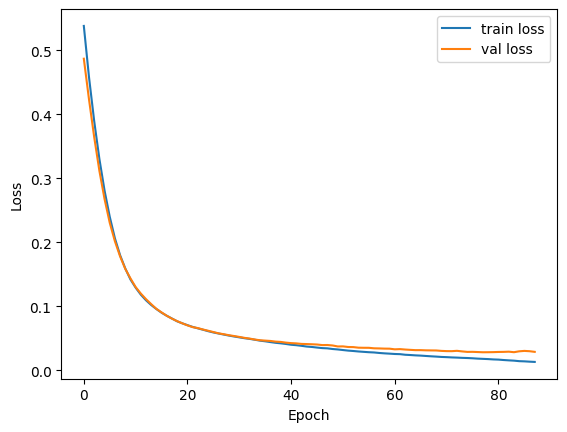

In [7]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.show()

#### Understanding the visualisation of Training and Validation Loss

###### 1. Plotting the Loss Curves

```python
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
```

This visualizes how the model's training and validation loss change across epochs.

- `history.history["loss"]`: Stores training loss after every epoch.
- `history.history["val_loss"]`: Stores validation loss after every epoch.
- `plt.xlabel("Epoch")`: Labels the X-axis.
- `plt.ylabel("Loss")`: Labels the Y-axis.
- `plt.legend()`: Displays labels for both curves.
- `plt.show()`: Displays the graph.

<br>

##### 2. Understanding the Loss Curves

The graph helps us understand whether the model is learning properly or overfitting.

###### **Healthy Learning**

  - Both training and validation loss decrease.
  - Both curves stay relatively close to each other.
  - The model is learning patterns that generalize well to unseen data.

###### **Overfitting**

  - Training loss continues decreasing.
  - Validation loss stops decreasing and starts increasing.
  - The gap between the two curves widens.

This indicates that the model is learning the training data increasingly well but performing worse on unseen validation data.

<br>

##### Understanding Our Graph

In our graph:

- Both training and validation loss decrease significantly.
- The curves stay close to each other throughout training.
- Towards the end, validation loss shows a small increase while training loss continues decreasing.

This suggests that the model is learning well, with a slight sign of possible overfitting towards the end.

<br>

##### 3. Key Takeaways

| Curve Behaviour | Interpretation |
|---|---|
| Both losses decrease | Healthy learning |
| Both losses stay close | Good generalization |
| Training loss decreases, validation loss increases | Overfitting |
| Both losses remain high | Possible underfitting |

## **Step 5: Making Predictions**

In [8]:
probs = model.predict(X_test)              # shape (114, 1), values in (0, 1)
preds = (probs > 0.5).astype(int).ravel()  # convert to 0/1 labels

print(probs[:5].ravel())
print(preds[:5], y_test[:5])

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
[7.2348733e-10 9.9999750e-01 5.8084239e-05 1.1987242e-01 3.1544574e-12]
[0 1 0 0 0] [0 1 0 1 0]


#### Understanding the code

##### 1. Generating Predictions

```python
probs = model.predict(X_test)
```

Uses the trained model to make predictions on the testing features.

- `X_test`: Contains unseen input features.
- `model.predict()`: Passes the testing data through the trained neural network.
- `probs`: Stores the predicted probabilities produced by the sigmoid output layer.

**Output shape:** `(114, 1)`

This means we have 114 test samples, with one predicted probability for each sample.

Each probability represents how likely the sample belongs to class `1` (Benign).

<br>

##### 2. Converting Probabilities into Class Labels

```python
preds = (probs > 0.5).astype(int).ravel()
```

Converts predicted probabilities into binary class labels (0 or 1).

- **`probs > 0.5`:** Applies a threshold of 0.5.
  - Probability greater than 0.5 → `True` (Class 1).
  - Probability less than or equal to 0.5 → `False` (Class 0).
- **`.astype(int)`:** Converts Boolean values into integers (`True = 1`, `False = 0`).
- **`.ravel()`:** Flattens the array from shape `(114, 1)` into `(114,)`.

<br>

##### 3. Printing Predictions and Actual Labels

```python
print(probs[:5].ravel())
print(preds[:5], y_test[:5])
```

**First line:**
- `probs[:5]` selects the first five predicted probabilities.
- `.ravel()` converts the output into a one-dimensional array.

**Second line:**
- `preds[:5]` displays the first five predicted class labels.
- `y_test[:5]` displays the corresponding actual class labels.

This allows us to compare the model's predictions with the actual answers.


**Remember:** Predicted probabilities tell us how confident the model is about a class, while predicted labels tell us which class the model selects.

### **Step 6: Evaluating the Model**

In [9]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

print(confusion_matrix(y_test, preds))
print(classification_report(y_test, preds, target_names=["malignant", "benign"]))

Test loss: 0.1008 | Test accuracy: 0.9561
[[40  2]
 [ 3 69]]
              precision    recall  f1-score   support

   malignant       0.93      0.95      0.94        42
      benign       0.97      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



#### 1. Evaluating the Model on Test Data

```python
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")
```

Evaluates the trained model using unseen testing data.

- **`model.evaluate()`:** Evaluates the model's performance on the testing dataset.
- **`X_test, y_test`:** Testing features and their actual labels.
- **`verbose=0`:** Suppresses the evaluation progress output.
- **`test_loss`:** Returns the Binary Crossentropy loss on the testing data.
- **`test_acc`:** Returns the classification accuracy on the testing data.

**Our output:**

```text
Test loss: 0.1008 | Test accuracy: 0.9561
```

- Test loss = `0.1008`
- Test accuracy = `95.61%`

This means the model correctly classified approximately 95.61% of the 114 testing samples.

<br>

#### Confusion Matrix

A confusion matrix is an evaluation tool used in classification to compare the model's predicted labels with the actual labels.

It shows the number of correct and incorrect predictions for each class.

```python
print(confusion_matrix(y_test, preds))
```

##### Our Output

```text
[[40  2]
 [ 3 69]]
```

##### **Understanding the Output**

In a confusion matrix:
- Rows represent **actual labels**.
- Columns represent **predicted labels**.

| Actual / Predicted | Malignant (0) | Benign (1) |
|---|---:|---:|
| Malignant (0) | 40 | 2 |
| Benign (1) | 3 | 69 |

##### **Interpreting the Results**

- **40:** Actual Malignant, predicted Malignant (correct).
- **2:** Actual Malignant, predicted Benign (incorrect).
- **3:** Actual Benign, predicted Malignant (incorrect).
- **69:** Actual Benign, predicted Benign (correct).

##### **Four Important Terms**

Treating Benign (class 1) as the positive class:

- **True Negative (TN) = 40:** Correctly predicted Malignant.
- **False Positive (FP) = 2:** Predicted Benign, but actually Malignant.
- **False Negative (FN) = 3:** Predicted Malignant, but actually Benign.
- **True Positive (TP) = 69:** Correctly predicted Benign.

**Key Takeaway:** The confusion matrix helps us understand exactly where our classification model makes correct and incorrect predictions, rather than relying on accuracy alone.

<br>

#### 3. Classification Report

```python
print(classification_report(
    y_test,
    preds,
    target_names=["malignant", "benign"]
))
```

Generates a detailed evaluation report containing precision, recall, F1-score and support for each class.

<br>

###### **Understanding the Metrics**

**Precision:**

Measures how many of the samples predicted as a particular class actually belong to that class.

$$
Precision=\frac{TP}{TP+FP}
$$

**Recall:**

Measures how many actual samples of a particular class the model correctly identifies.

$$
Recall=\frac{TP}{TP+FN}
$$

**F1-Score:**

The harmonic mean of precision and recall. It balances both metrics into a single score.

$$
F1=2\times\frac{Precision\times Recall}{Precision+Recall}
$$

**Support:**

The total number of actual samples belonging to each class in the testing dataset.

<br>

#### Understanding Our Output

| Class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Malignant | 0.93 | 0.95 | 0.94 | 42 |
| Benign | 0.97 | 0.96 | 0.97 | 72 |

- **Malignant:** Out of the samples predicted as malignant, 93% were actually malignant. The model identified 95% of all actual malignant samples.
- **Benign:** Out of the samples predicted as benign, 97% were actually benign. The model identified 96% of all actual benign samples.

<br>

#### Average Scores

- **Macro Average:** Calculates the unweighted average of each metric across both classes. Each class gets equal importance.
- **Weighted Average:** Calculates the average while considering the number of actual samples in each class (support).